# Figure 2: Cross-Modal Retrieval

Compares scaffold-cluster splits, Tanimoto similarity distributions, and cross-modal retrieval performance between morphology and structure embeddings.

This notebook generates:
1. Pie chart of scaffold-cluster size distribution
2. Histogram of scaffold-cluster sizes
3. Density comparison of cluster-scaffold vs. scaffold split Tanimoto similarity
4. Multimodal retrieval bar plots (standard and plate-matched)

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))

%matplotlib inline

from scipy.stats import gaussian_kde, ranksums
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

BASE_DIR = str(REPO_ROOT)

# Setup publication-quality matplotlib style
setup_publication_style(BASE_DIR)

# Output directories
DATA_DIR = os.path.join(BASE_DIR, "data", "gmc_jump_plots")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "gmc_jump_plots")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = False

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Load JUMP Data

In [2]:
from phenocompass.data.dataset import FastH5DatasetJUMP

h5_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_dino_tvn.h5")
index_predetermined_file = os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_cluster_splits.pkl")

dataset = FastH5DatasetJUMP(
    h5_path, avg_morph_feat=True, index_predetermined_file=index_predetermined_file,
    ohe_batch=True, graph_data=os.path.join(FINAL_DATA_DIR, "jump_map", "mol_struct.pickle")
)

## 3. Scaffold-Cluster Splits

In [3]:
# Load cluster data
cluster_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_clusters.parquet"))
cluster_df.index = cluster_df["smiles"].values

cluster_df = cluster_df.loc[dataset.ids]
cluster_df["jump_idx"] = np.arange(len(cluster_df))

# Cluster size binning for pie chart
cluster_size_df = cluster_df[cluster_df["cluster"] != "-1"]["cluster"].value_counts().reset_index()

bins = [1, 5, 10, 50, 100, 10000]
cluster_size_df["bucket"] = pd.cut(cluster_size_df["count"], bins=bins)

cluster_size_bin_counts_df = cluster_size_df["bucket"].value_counts().reset_index()
cluster_size_bin_counts_df = cluster_size_bin_counts_df.sort_values("bucket")

cluster_size_bin_counts_df["percent"] = cluster_size_bin_counts_df["count"] / cluster_size_bin_counts_df["count"].sum()
cluster_size_bin_counts_df

,bucket,count,percent
4,"(1, 5]",39,0.010487
2,"(5, 10]",238,0.063996
0,"(10, 50]",3125,0.840280
1,"(50, 100]",277,0.074482
3,"(100, 10000]",40,0.010756


### 3.1 Cluster Scaffold vs. Scaffold Tanimoto Similarity

Wilcoxon (less): z=-20.414, p=6.302e-93

--- Statistical Tests ---
                              comparison             test  statistic      p_value alternative
Scaffold-Cluster Split vs Scaffold Split wilcoxon_ranksum -20.413818 6.302194e-93        less
Figure already exists


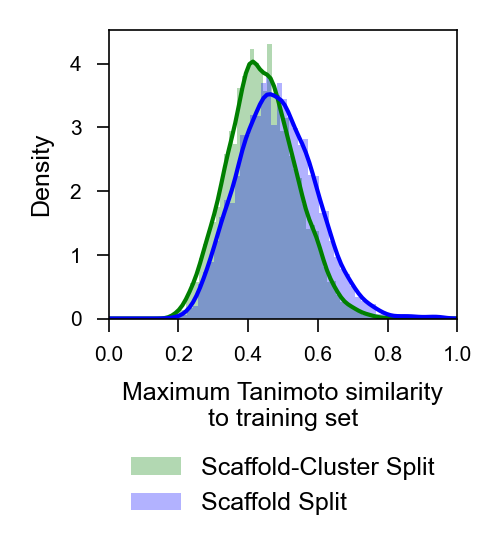

In [4]:
cluster_scaffold_tanimoto_sim_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "jump_map/cluster_scaffold.tanimoto_similarities.parquet"))
scaffold_tanimoto_sim_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_split.tanimoto_similarities.parquet"))

plt.figure(figsize=(1.5, 1.25))

plt.hist(cluster_scaffold_tanimoto_sim_df["max_tanimoto_sim"].values,
         bins=50, density=True, label="Scaffold-Cluster Split", alpha=0.3, color="green")
plt.hist(scaffold_tanimoto_sim_df["max_tanimoto_sim"].values,
         bins=50, density=True, label="Scaffold Split", alpha=0.3, color="blue")
plt.plot(np.linspace(0, 1, 100),
         gaussian_kde(cluster_scaffold_tanimoto_sim_df["max_tanimoto_sim"].values)(np.linspace(0, 1, 100)),
         linewidth=1, color="green")
plt.plot(np.linspace(0, 1, 100),
         gaussian_kde(scaffold_tanimoto_sim_df["max_tanimoto_sim"].values)(np.linspace(0, 1, 100)),
         linewidth=1, color="blue")

plt.xlabel("Maximum Tanimoto similarity\nto training set")
plt.ylabel("Density")
plt.legend(bbox_to_anchor=(1, -0.4), frameon=False)
plt.xlim([0, 1])

cluster_vals = cluster_scaffold_tanimoto_sim_df["max_tanimoto_sim"].values
scaffold_vals = scaffold_tanimoto_sim_df["max_tanimoto_sim"].values
comparison = "Scaffold-Cluster Split vs Scaffold Split"

# Wilcoxon rank-sum test (one-sided, less)
z, p_w = ranksums(cluster_vals, scaffold_vals, alternative="less")
print("Wilcoxon (less): z={:.3f}, p={:.3e}".format(z, p_w))

# Collect stats into a DataFrame
stats_records = [
    {"comparison": comparison, "test": "wilcoxon_ranksum", "statistic": z, "p_value": p_w, "alternative": "less"},
]
stats_df = pd.DataFrame(stats_records)
print("\n--- Statistical Tests ---")
print(stats_df.to_string(index=False))

fig_path = os.path.join(FIGURE_DIR, "FigS4_jump_train_test_pairwise_tanimoto_sim_comparison.pdf")
save_figure(fig_path, FORCE_RECOMPUTE)

## 4. GNEprop Embeddings UMAP

## 5. Multimodal Retrieval

In [5]:
convert_name_dict = {
    "Curated Features": "PhenoCompass (Curated Features)",
    "GNEprop": "PhenoCompass (GNEprop)",
    "linear_regression": "GNEprop Embeddings + Linear Regression",
    "mf_linear_regression": "Morgan Fingerprints + Linear Regression",
    "knn_regression": "GNEprop Embeddings + kNN Regression",
    "mf_knn_regression": "Morgan Fingerprints + kNN Regression",
    "mf_mlp": "Morgan Fingerprints + MLP Regression",
    "gneprop_mlp": "GNEprop Embeddings + MLP Regression",
}

method_rank_list = [
    "Morgan Fingerprints + Linear Regression",
    "Morgan Fingerprints + kNN Regression",
    "Morgan Fingerprints + MLP Regression",
    "GNEprop Embeddings + Linear Regression",
    "GNEprop Embeddings + kNN Regression",
    "GNEprop Embeddings + MLP Regression",
    "PhenoCompass (Curated Features)",
    "PhenoCompass (GNEprop)",
]

palette = {
    "PhenoCompass (Curated Features)": "cornflowerblue",
    "PhenoCompass (GNEprop)": "royalblue",
    "GNEprop Embeddings + Linear Regression": "green",
    "GNEprop Embeddings + kNN Regression": "limegreen",
    "GNEprop Embeddings + MLP Regression": "lightgreen",
    "Morgan Fingerprints + Linear Regression": "red",
    "Morgan Fingerprints + kNN Regression": "tomato",
    "Morgan Fingerprints + MLP Regression": "lightsalmon",
}

### 5.1 Standard Retrieval

morph>struct


Figure already exists


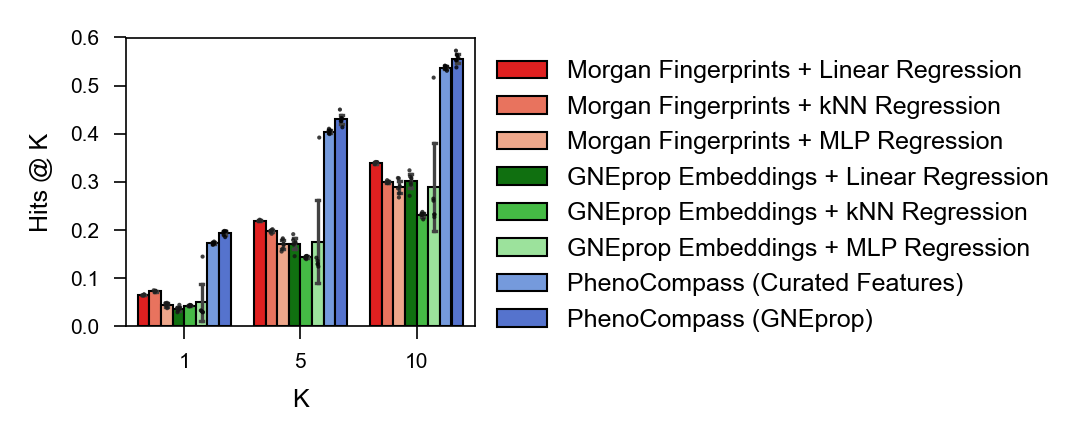

struct>morph


Figure already exists


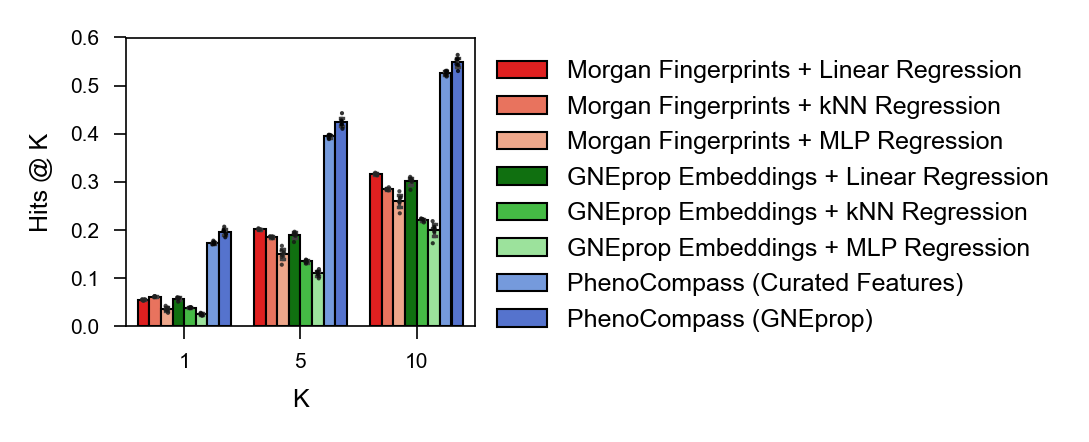

In [6]:
coembedding_updated_results_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/phenocompass.crossmodal_retrieval_results.parquet"))
baseline_updated_results_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/baselines.crossmodal_retrieval_results.parquet"))

updated_results_df = pd.concat([coembedding_updated_results_df, baseline_updated_results_df])
updated_results_df["method"] = updated_results_df["method"].map(convert_name_dict)
updated_results_df["method_rank"] = updated_results_df["method"].map({n: i for i, n in enumerate(method_rank_list)})
updated_results_df = updated_results_df.sort_values(["K", "method_rank"])
updated_results_df["K"] = updated_results_df["K"].astype(int)

for n, group_df in updated_results_df.groupby("lookup"):
    print(n)
    plt.figure(figsize=(1.5, 1.25))
    ax = sns.barplot(x="K", y="value", hue="method", data=group_df,
                     capsize=0.2, errorbar=("se", 2), palette=palette, edgecolor="black",
                     err_kws={'linewidth': 0.8}, linewidth=0.5)
    sns.stripplot(x="K", y="value", hue="method", data=group_df, color="black",
                  dodge=True, alpha=0.8, size=1)
    plt.xlabel("K")
    plt.ylabel("Hits @ K")

    handles, labels = ax.get_legend_handles_labels()
    handles = handles[0:len(handles) // 2]
    labels = labels[0:len(labels) // 2]

    plt.ylim([0, 0.6])
    plt.legend(handles, labels, bbox_to_anchor=(1, 1), frameon=False)

    fig_path = os.path.join(FIGURE_DIR, "Fig2_{}.multimodal_retrieval_results.pdf".format(n.replace(">", "_")))
    save_figure(fig_path, FORCE_RECOMPUTE)

In [7]:
mean_coembedding_updated_results_df = coembedding_updated_results_df.groupby(["metric", "method"])["value"].mean().reset_index()
gneprop_mean_coembedding_updated_results_df = mean_coembedding_updated_results_df[mean_coembedding_updated_results_df["method"] == "GNEprop"]
mean_baseline_updated_results_df = baseline_updated_results_df.groupby(["metric", "method"])["value"].mean().reset_index()

for metric, max_baseline_value in mean_baseline_updated_results_df.groupby("metric")["value"].max().reset_index().values:
    print(metric, gneprop_mean_coembedding_updated_results_df[gneprop_mean_coembedding_updated_results_df["metric"] == metric]["value"].values / max_baseline_value)

morph>struct_h1 [2.65713346]
morph>struct_h10 [1.63827832]
morph>struct_h5 [1.95836521]
struct>morph_h1 [3.18659914]
struct>morph_h10 [1.73474499]
struct>morph_h5 [2.10282042]


### 5.2 Plate-Matched Retrieval

morph>struct


Figure already exists


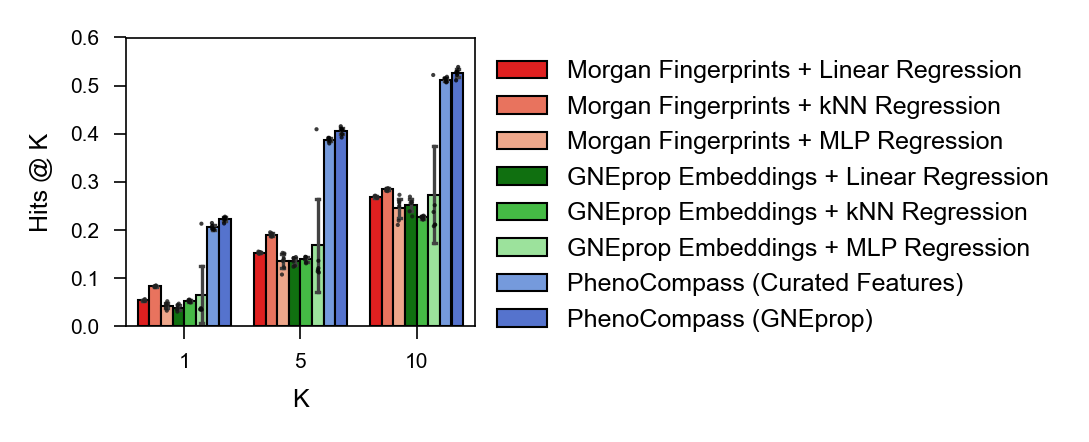

struct>morph


Figure already exists


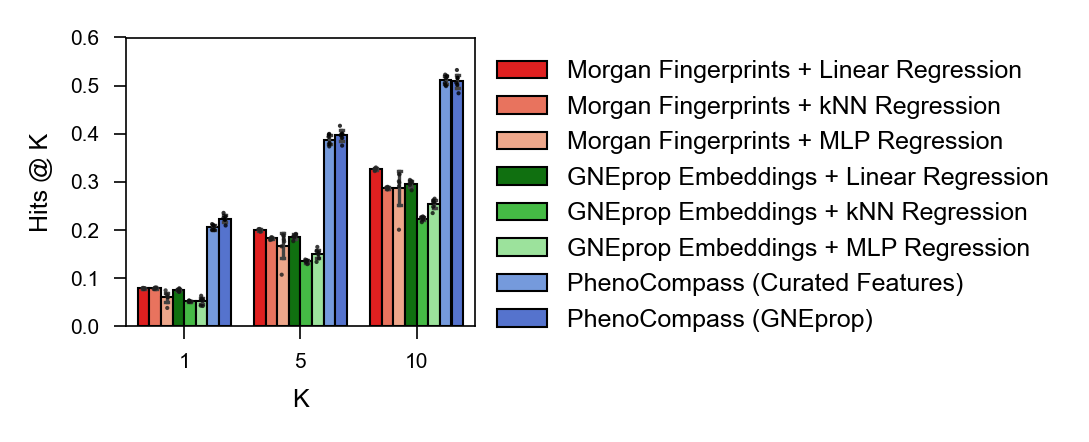

In [8]:
coembedding_updated_results_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/phenocompass.crossmodal_retrieval_results.plate_matched.parquet"))
baseline_updated_results_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/baselines.crossmodal_retrieval_results.plate_matched.parquet"))

updated_results_df = pd.concat([coembedding_updated_results_df, baseline_updated_results_df])
updated_results_df["method"] = updated_results_df["method"].map(convert_name_dict)
updated_results_df["method_rank"] = updated_results_df["method"].map({n: i for i, n in enumerate(method_rank_list)})
updated_results_df = updated_results_df.sort_values(["K", "method_rank"])
updated_results_df["K"] = updated_results_df["K"].astype(int)

for n, group_df in updated_results_df.groupby("lookup"):
    print(n)
    plt.figure(figsize=(1.5, 1.25))
    ax = sns.barplot(x="K", y="value", hue="method", data=group_df,
                     capsize=0.2, errorbar=("se", 2), palette=palette, edgecolor="black",
                     err_kws={'linewidth': 0.8}, linewidth=0.5)
    sns.stripplot(x="K", y="value", hue="method", data=group_df, color="black",
                  dodge=True, alpha=0.8, size=1)
    plt.xlabel("K")
    plt.ylabel("Hits @ K")

    handles, labels = ax.get_legend_handles_labels()
    handles = handles[0:len(handles) // 2]
    labels = labels[0:len(labels) // 2]

    plt.ylim([0, 0.6])
    plt.legend(handles, labels, bbox_to_anchor=(1, 1), frameon=False)

    fig_path = os.path.join(FIGURE_DIR, "FigS5_{}.multimodal_retrieval_results.plate_matched.pdf".format(n.replace(">", "_")))
    save_figure(fig_path, FORCE_RECOMPUTE)

In [9]:
mean_coembedding_updated_results_df = coembedding_updated_results_df.groupby(["metric", "method"])["value"].mean().reset_index()
gneprop_mean_coembedding_updated_results_df = mean_coembedding_updated_results_df[mean_coembedding_updated_results_df["method"] == "GNEprop"]
mean_baseline_updated_results_df = baseline_updated_results_df.groupby(["metric", "method"])["value"].mean().reset_index()

for metric, max_baseline_value in mean_baseline_updated_results_df.groupby("metric")["value"].max().reset_index().values:
    print(metric, gneprop_mean_coembedding_updated_results_df[gneprop_mean_coembedding_updated_results_df["metric"] == metric]["value"].values / max_baseline_value)

morph>struct_h1 [2.67725173]
morph>struct_h10 [1.85059509]
morph>struct_h5 [2.12791137]
struct>morph_h1 [2.82206729]
struct>morph_h10 [1.55970314]
struct>morph_h5 [1.980465]


In [10]:
# Save figure source data for manuscript reproducibility

# Cluster size and Tanimoto comparison data
cluster_tanimoto_data = []

# Add Tanimoto density comparison data
for ts_val in cluster_scaffold_tanimoto_sim_df["max_tanimoto_sim"].values:
    cluster_tanimoto_data.append({
        "data_type": "tanimoto_density",
        "max_tanimoto_sim": ts_val,
        "split_type": "Scaffold-Cluster"
    })

for ts_val in scaffold_tanimoto_sim_df["max_tanimoto_sim"].values:
    cluster_tanimoto_data.append({
        "data_type": "tanimoto_density",
        "max_tanimoto_sim": ts_val,
        "split_type": "Scaffold"
    })

cluster_tanimoto_df = pd.DataFrame(cluster_tanimoto_data)

fig_data_path = os.path.join(FIGURE_DIR, "FigS4_gmc_cluster_tanimoto_data.tsv")
save_figure_data(cluster_tanimoto_df, fig_data_path, FORCE_RECOMPUTE)

# Save Wilcoxon rank-sum test results
stats_path = os.path.join(FIGURE_DIR, "FigS4_gmc_cluster_tanimoto_stats.tsv")
save_figure_data(stats_df, stats_path, FORCE_RECOMPUTE)

# Retrieval results data (combining standard and plate-matched)
# Standard retrieval
std_coembed = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/phenocompass.crossmodal_retrieval_results.parquet"))
std_baseline = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/baselines.crossmodal_retrieval_results.parquet"))
std_combined = pd.concat([std_coembed, std_baseline])
std_combined["plate_matched"] = False

# Plate-matched retrieval
pm_coembed = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/phenocompass.crossmodal_retrieval_results.plate_matched.parquet"))
pm_baseline = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "crossmodal_retrieval/baselines.crossmodal_retrieval_results.plate_matched.parquet"))
pm_combined = pd.concat([pm_coembed, pm_baseline])
pm_combined["plate_matched"] = True

# Combine all retrieval results
all_retrieval_df = pd.concat([std_combined, pm_combined], ignore_index=True)
all_retrieval_df["method"] = all_retrieval_df["method"].map(convert_name_dict)
all_retrieval_df["method_rank"] = all_retrieval_df["method"].map({n: i for i, n in enumerate(method_rank_list)})

fig_data_path = os.path.join(FIGURE_DIR, "Fig2_S5_gmc_retrieval_results_data.tsv")
save_figure_data(all_retrieval_df, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists
Figure data already exists
Figure data already exists
